In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# data: column 1 = time (days), column 2 = noisy y(t)^2, no header
t, z = np.loadtxt("data/data.csv", delimiter=",", unpack=True)

def y_model(t, lam1, lam2):
    return (np.exp(lam1 * t) - np.exp(lam2 * t)) / (lam1 - lam2)

def z_model(t, lam1, lam2):
    return y_model(t, lam1, lam2) ** 2

def exp_model(t, a, b, c):
    return a + b * np.exp(c * t)

def sse(fit):
    return np.sum((z - fit) ** 2)

def r2(fit):
    return 1 - sse(fit) / np.sum((z - z.mean()) ** 2)

In [2]:
popt, _ = curve_fit(z_model, t, z, p0=[0.3, -0.5], maxfev=10000)
lam1, lam2 = max(popt), min(popt)      # label the larger root lambda_1
fit_seir = z_model(t, lam1, lam2)

print(f"lambda_1 = {lam1:.4f}, lambda_2 = {lam2:.4f}")
print(f"sigma + gamma     = {-(lam1 + lam2):.4f}")
print(f"sigma(beta-gamma) = {-lam1 * lam2:.4f}")
print(f"SSE = {sse(fit_seir):.0f}, R^2 = {r2(fit_seir):.4f}")

lambda_1 = 0.2097, lambda_2 = -0.5104
sigma + gamma     = 0.3006
sigma(beta-gamma) = 0.1070
SSE = 20541, R^2 = 0.8071


In [3]:
# exponential g(t) = a + b exp(ct)
(a, b, c), _ = curve_fit(exp_model, t, z, p0=[0, 1, 0.4], maxfev=10000)
fit_exp = exp_model(t, a, b, c)
print(f"a = {a:.3f}, b = {b:.3f}, c = {c:.4f}  (c/2 = {c/2:.4f})")
print(f"exponential: SSE = {sse(fit_exp):.0f}, R^2 = {r2(fit_exp):.4f}\n")

# polynomials of degree 1, 2, 3 (coefficients printed highest power first)
fit_poly = {}
for n in (1, 2, 3):
    coef = np.polyfit(t, z, n)
    fit_poly[n] = np.polyval(coef, t)
    print(f"degree {n}: coefficients {np.round(coef, 4)}, "
          f"SSE = {sse(fit_poly[n]):.0f}, R^2 = {r2(fit_poly[n]):.4f}")

a = -1.651, b = 2.070, c = 0.4139  (c/2 = 0.2069)
exponential: SSE = 20461, R^2 = 0.8079

degree 1: coefficients [ 5.8279 -8.4206], SSE = 33508, R^2 = 0.6854
degree 2: coefficients [ 1.1651 -3.4926  3.9756], SSE = 20998, R^2 = 0.8028
degree 3: coefficients [ 0.1305 -0.4014  1.5138  0.6588], SSE = 20349, R^2 = 0.8089


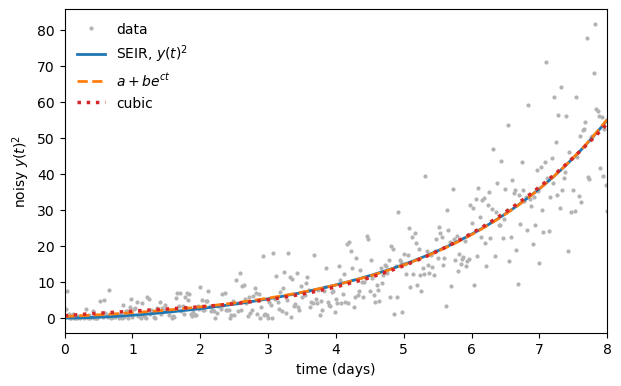

In [4]:
plt.figure(figsize=(7, 4.2))
plt.plot(t, z, ".", color="0.7", markersize=4, label="data")
plt.plot(t, fit_seir, "-", color="C0", linewidth=2, label=r"SEIR, $y(t)^2$")
plt.plot(t, fit_exp, "--", color="C1", linewidth=2, label=r"$a+be^{ct}$")
plt.plot(t, fit_poly[3], ":", color="C3", linewidth=2.5, label="cubic")
plt.xlabel("time (days)")
plt.ylabel(r"noisy $y(t)^2$")
plt.legend(frameon=False)
plt.xlim(t.min(), t.max())
plt.show()